# Drosophila segment polarity patterning

This notebook reproduces the analysis of the Drosophila patterning model of the
[MaBoSS website](https://maboss.curie.fr).

The model of the segment polarity genes is based on a published model
([Sánchez and Thieffry, 2003](https://doi.org/10.1016/s0022-5193(03)00035-3)), and the analysis on another
publication ([Chaves and Albert, 2008](https://doi.org/10.1098/rsif.2008.0132.focus)), which studied the
effect of random noise on this network.

The model consists of four identical signaling pathways, one for each of four adjacent cells, connected to
each other (cell 1 is adjacent to cell 4). mRNA (lower case, e.g. `en1`) and proteins (upper case, e.g. `EN1`)
are considered separately. Two transition rates are used: `$rate_RNA = 1` for transcriptional influences, and
`$rate_protein = 10` for post-transcriptional influences. Random noise on every node is tuned by the parameter
`$noise`.

**Requirements:** [pyMaBoSS](https://pymaboss.readthedocs.io/), and the files `D_Pattern_ContT.bnd`,
`D_Pattern_ContT_noIntNode.cfg`, `D_Pattern_ContT_noIntNode_noise.cfg` and
`D_Pattern_ContT_noIntNode_noise_4statdist.cfg`, in the same folder as this notebook.

In [1]:
import os
import maboss
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

# Common style for the figures of the MaBoSS website notebooks
COLORS = ["#FF7F00", "#1F77B4", "#2CA02C", "#D62728", "#9467BD",
          "#8C564B", "#E377C2", "#17BECF", "#BCBD22", "#7F7F7F"]
mpl.rcParams.update({
    "figure.figsize": (7, 4),
    "figure.dpi": 100,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
    "axes.prop_cycle": mpl.cycler(color=COLORS),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "legend.frameon": False,
    "lines.linewidth": 2,
})

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save(fig, name):
    """Save a figure in the figures folder."""
    fig.savefig(os.path.join(FIG_DIR, name + ".png"))

def state_label(state):
    """Readable label for a MaBoSS state."""
    return "none active" if state == "<nil>" else state.replace(" -- ", ", ")

def pie(probas, ax, title=None, min_proba=0.01, labels=None):
    """Pie chart of a distribution; probabilities below min_proba are grouped as 'others'."""
    probas = pd.Series(probas).sort_values(ascending=False)
    small = probas[probas < min_proba]
    probas = probas[probas >= min_proba]
    if len(small) > 0:
        probas["others"] = small.sum()
    names = [labels.get(s, state_label(s)) if labels else state_label(s) for s in probas.index]
    colors = [COLORS[i % len(COLORS)] if s != "others" else "#D9D9D9" for i, s in enumerate(probas.index)]
    wedges, _ = ax.pie(probas.values, colors=colors, startangle=90, counterclock=False,
                       wedgeprops={"linewidth": 1, "edgecolor": "white"})
    ax.legend(wedges, [f"{n} ({p:.1%})" for n, p in zip(names, probas.values)],
              loc="center left", bbox_to_anchor=(1, 0.5))
    ax.set_aspect("equal")
    if title:
        ax.set_title(title)

def set_refstate_all(sim, value=0):
    """Give a reference state to every node.

    With MaBoSS 2.6.6, the states of the stationary distributions only include the nodes
    having a reference state; this makes them include all the nodes, as in previous versions.
    """
    for node in sim.network:
        if node not in sim.refstate:
            sim.refstate[node] = value

ipylab module is not installed, menus and toolbar are disabled.


## Patterns

A state of the network is a pattern: the activity of each gene in each of the four cells. We define a function
to draw it.

In [2]:
GENES = ["wg", "WG", "en", "EN", "hh", "HH", "ptc", "PTC", "ci", "CI", "CIA", "CIR", "SLP"]
CELLS = [1, 2, 3, 4]

def pattern(active):
    """Pattern (genes x cells) of a set of active nodes."""
    return pd.DataFrame([[int(f"{gene}{cell}" in active) for cell in CELLS] for gene in GENES],
                        index=GENES, columns=[f"cell {c}" for c in CELLS])

def plot_pattern(active, ax, title):
    ax.imshow(pattern(active).values, cmap=mpl.colors.ListedColormap(["#EEEEEE", COLORS[0]]),
              vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(CELLS)), [str(c) for c in CELLS])
    ax.set_xlabel("cell")
    ax.set_yticks(range(len(GENES)), GENES)
    ax.set_xticks(np.arange(-0.5, len(CELLS)), minor=True)
    ax.set_yticks(np.arange(-0.5, len(GENES)), minor=True)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.grid(which="major", visible=False)
    ax.tick_params(which="both", length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title(title)

def active_nodes(state):
    return set() if state == "<nil>" else set(state.split(" -- "))

The model should produce the expected patterning (the reference state, in which none of the four cells are
identical) starting from the initial state below, when the pair rule gene SLP has the pattern SLP1,2 = 0 and
SLP3,4 = 1. The reference state is used to compute the Hamming distance distribution: the probability that a
state differs from the reference state on a given number of nodes.

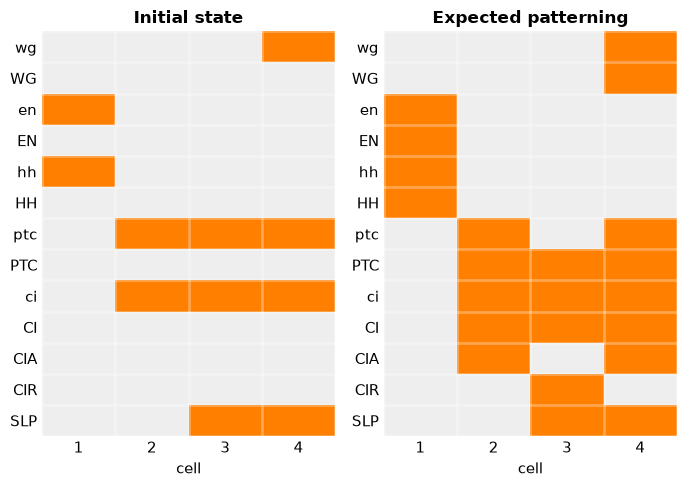

In [3]:
no_noise = maboss.load("D_Pattern_ContT.bnd", "D_Pattern_ContT_noIntNode.cfg")

initial = {node for node, value in no_noise.get_initial_state().items() if value == 1}
reference = {node for node, value in no_noise.refstate.items() if value} | {"SLP3", "SLP4"}

fig, axes = plt.subplots(1, 2, figsize=(7, 5))
plot_pattern(initial, axes[0], "Initial state")
plot_pattern(reference, axes[1], "Expected patterning")
fig.tight_layout()
save(fig, "droso_initial_reference")

## Simulations

We consider two cases: no noise (`$noise = 0`) and low noise (`$noise = 0.01`).

For the trajectories of the Hamming distance distribution, the nodes do not need to be visible in the results:
we declare all of them as internal, which keeps the output files small, as the noisy simulation visits a very
large number of states.

In [4]:
def hide_all_nodes(sim):
    for node in sim.network:
        sim.network[node].is_internal = True

hide_all_nodes(no_noise)
no_noise.update_parameters(statdist_traj_count=0)
result_no_noise = no_noise.run()

noise = maboss.load("D_Pattern_ContT.bnd", "D_Pattern_ContT_noIntNode_noise.cfg")
hide_all_nodes(noise)
noise.update_parameters(statdist_traj_count=0)
result_noise = noise.run()

In [5]:
def plot_hamming(result, title, min_proba=0.05):
    """Trajectories of the Hamming distance distribution: the main values in color, the others in grey."""
    hd = pd.read_csv(result.get_probtraj_file(), sep="\t", index_col=0,
                     usecols=lambda c: c == "Time" or c.startswith("HD="))
    hd = hd.loc[:, hd.max() > 0]
    main = [c for c in hd.columns if c != "HD=0" and hd[c].iloc[len(hd) // 10:].max() >= min_proba]
    fig, ax = plt.subplots(figsize=(8, 4))
    others = [c for c in hd.columns if c != "HD=0" and c not in main]
    for i, column in enumerate(others):
        ax.plot(hd.index, hd[column], color="#C8C8C8", linewidth=1, label="other values" if i == 0 else None)
    for i, column in enumerate(main):
        ax.plot(hd.index, hd[column], color=COLORS[i % len(COLORS)], linewidth=2, label=column.replace("=", " = "))
    ax.plot(hd.index, hd["HD=0"], color="black", linewidth=3, label="HD = 0 (expected patterning)")
    ax.set_xlabel("Time")
    ax.set_ylabel("Probability")
    ax.set_title(title)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[::-1], labels[::-1], loc="center left", bbox_to_anchor=(1, 0.5))
    return fig

## Without noise

When there is no noise, the expected patterning is reached. This can be seen on the trajectories of the Hamming
distance distribution (HD), with the expected patterning as the reference state.

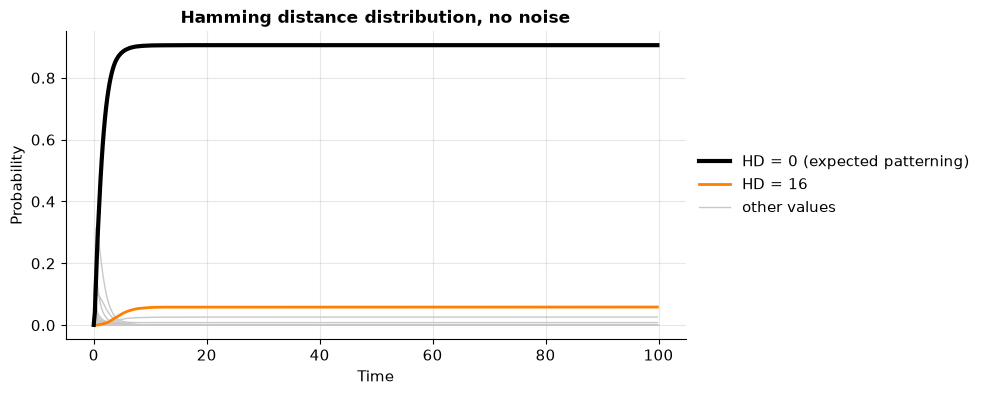

In [6]:
fig = plot_hamming(result_no_noise, "Hamming distance distribution, no noise")
save(fig, "droso_hd_no_noise")

The asymptotic behavior consists of fixed points. We compute the Hamming distance of each of them to the expected
patterning: the most probable fixed point is the expected patterning.

In [7]:
fixed_points = result_no_noise.get_fptable().sort_values("Proba", ascending=False).reset_index(drop=True)
fixed_points["active"] = [{n for n in fixed_points.columns[3:] if row[n] == 1} for _, row in fixed_points.iterrows()]
fixed_points["HD"] = [len((active ^ reference) - {"SLP1", "SLP2", "SLP3", "SLP4"}) for active in fixed_points["active"]]
fixed_points["name"] = [("expected patterning" if hd == 0 else f"fixed point {i + 1}, HD = {hd}")
                        for i, hd in enumerate(fixed_points["HD"])]
fixed_points[["name", "Proba", "HD"]]

,name,Proba,HD
0,expected patterning,0.90562,0
1,"fixed point 2, HD = 16",0.05856,16
2,"fixed point 3, HD = 14",0.02616,14
3,"fixed point 4, HD = 1",0.00844,1
4,"fixed point 5, HD = 27",0.00092,27
5,"fixed point 6, HD = 28",0.00030,28


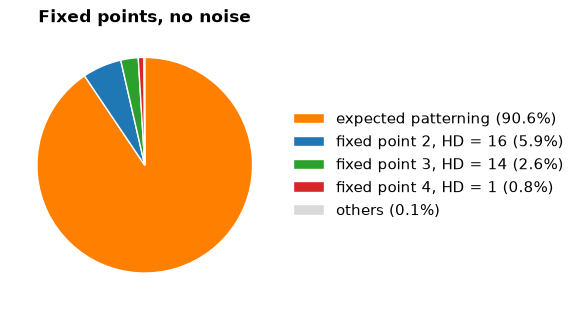

In [8]:
fig, ax = plt.subplots(figsize=(6, 3.5))
pie(fixed_points.set_index("name")["Proba"], ax, "Fixed points, no noise", min_proba=0.005)
save(fig, "droso_fixed_points")

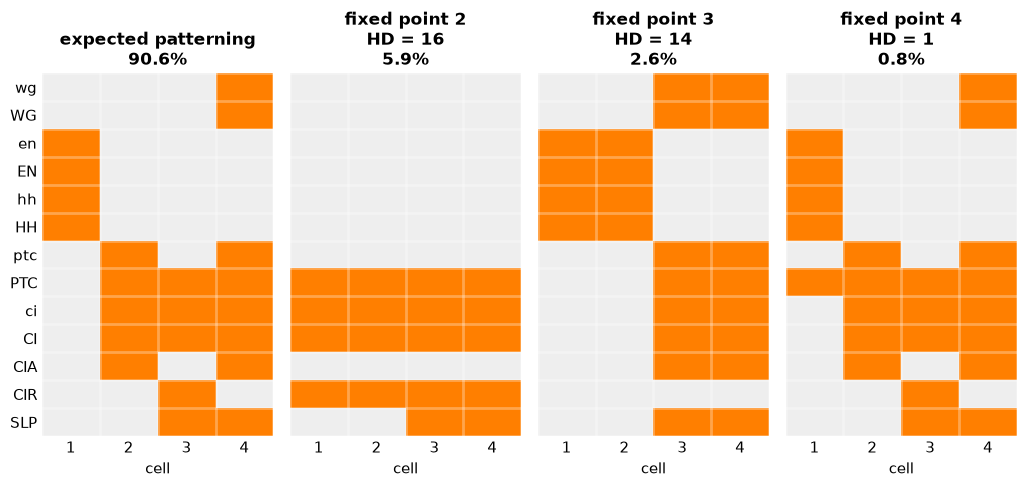

In [9]:
def plot_patterns(states, titles, name):
    fig, axes = plt.subplots(1, len(states), figsize=(2.6 * len(states), 5), sharey=True)
    for ax, active, title in zip(axes, states, titles):
        plot_pattern(active, ax, title)
    fig.tight_layout()
    save(fig, name)

top = fixed_points.head(4)
plot_patterns(top["active"], [f"{n}\n{p:.1%}".replace(", ", "\n", 1) for n, p in zip(top["name"], top["Proba"])],
              "droso_fixed_points_patterns")

## With noise

When there is noise, the expected patterning is no longer stable.

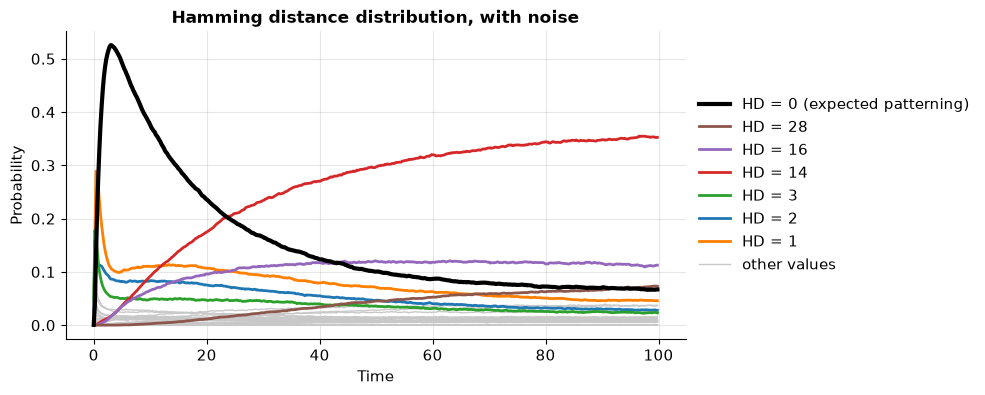

In [10]:
fig = plot_hamming(result_noise, "Hamming distance distribution, with noise")
save(fig, "droso_hd_noise")

With random noise on the nodes, there is only one indecomposable stationary distribution, in which all the
network states have a non-zero probability. The clustering of stationary distributions would then artificially
separate the estimates: a specific configuration file is used, with a longer maximum time, fewer trajectories,
and a clustering threshold set to 0.

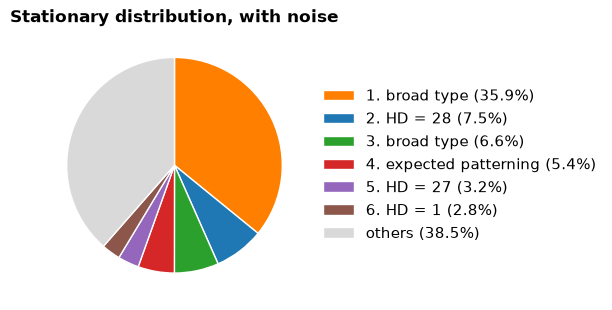

In [11]:
stationary = maboss.load("D_Pattern_ContT.bnd", "D_Pattern_ContT_noIntNode_noise_4statdist.cfg")
result_stationary = stationary.run()
distribution = result_stationary.get_statdist_clusters_summary().iloc[0].dropna().sort_values(ascending=False)

def describe(state):
    """Name a state according to its pattern."""
    active = active_nodes(state) | {"SLP3", "SLP4"}
    if not (active ^ reference):
        return "expected patterning"
    p = pattern(active)
    if any(p[f"cell {c}"].equals(p[f"cell {c % 4 + 1}"]) for c in CELLS):
        return "broad type"
    return f"HD = {len(active ^ reference)}"

names = {state: f"{i + 1}. {describe(state)}" for i, state in enumerate(distribution.index)}

fig, ax = plt.subplots(figsize=(6, 3.5))
pie(distribution, ax, "Stationary distribution, with noise", min_proba=0.02, labels=names)
save(fig, "droso_stationary_noise")

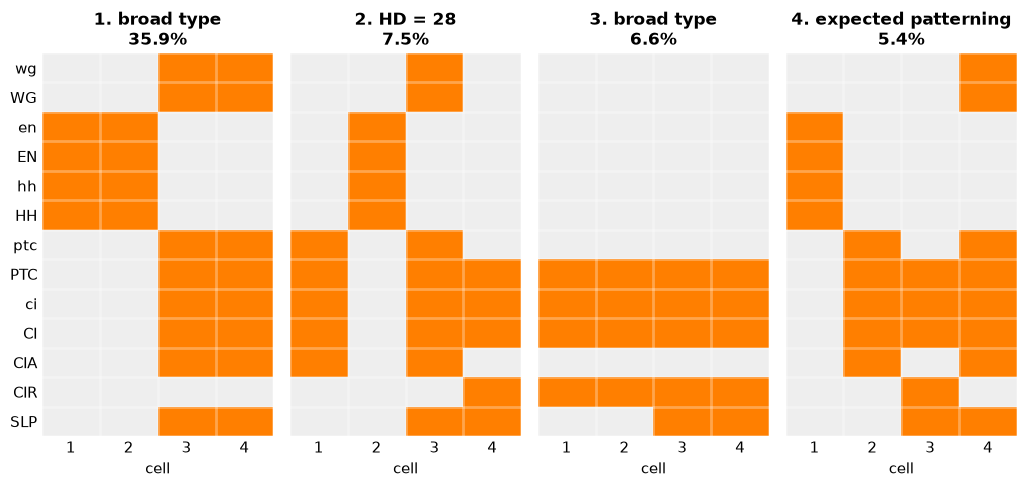

In [12]:
top = distribution.head(4)
plot_patterns([active_nodes(s) | {"SLP3", "SLP4"} for s in top.index],
              [f"{names[s]}\n{p:.1%}" for s, p in top.items()], "droso_stationary_noise_patterns")

The most probable state corresponds to a "broad type" patterning, as defined in the publications above:
two adjacent cells have identical node states.